# Nonrandom split: application-only versus additional data

Compare the same 64 → 32 → 1 network with application inputs only, with 21 bureau/installment features, with those features plus credit-card history, and with application plus credit-card features only. The split is fixed **before training** using loan amount: at/below the 60th percentile for training, above that through the 80th percentile for validation, and above the 80th percentile for an unscored test set. Equal amounts stay together, so sizes may differ from 60/20/20.

This tests transfer from smaller to larger loans. It is a distribution-shift stress test, not a justified deployment simulation without evidence that future applicants request larger loans. Amount boundaries use only the feature distribution, not labels or model performance. No boundary is tuned for a better result.

All four models use the same applicant IDs, seed 42, 15 epochs, batch size 256, Adam learning rate 0.001, training-only preprocessing, best-validation-AUC checkpoint, and validation-F1 threshold selection. Only the input feature set changes; the wider input layer necessarily has more parameters. Earlier project work already examined this dataset; this is not a new untouched holdout.

In [1]:
from pathlib import Path
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, precision_score, recall_score

SEED = 42
EPOCHS = 15
BATCH_SIZE = 256
LEARNING_RATE = 0.001

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running on:", device)
from sklearn.metrics import confusion_matrix
torch.set_num_threads(1)
from sklearn.metrics import roc_curve

Running on: cpu


## 1. Load and merge the additional features

In [2]:
df = pd.read_csv('application_train.csv')
extra = pd.read_csv('history_feature_artifacts/additional_data_features.csv')
assert df.SK_ID_CURR.is_unique and extra.SK_ID_CURR.is_unique
history_flags = ['BUREAU_HAS_HISTORY', 'INST_HAS_HISTORY']
history_numeric = [c for c in extra if c not in ['SK_ID_CURR', *history_flags]]
merged = df.join(extra.set_index('SK_ID_CURR'), on='SK_ID_CURR', validate='one_to_one')
merged[history_flags] = merged[history_flags].fillna(0).astype(int)
assert merged.index.equals(df.index) and merged.SK_ID_CURR.equals(df.SK_ID_CURR)
assert merged.TARGET.equals(df.TARGET)
assert len(history_numeric) + len(history_flags) == 21
X = merged.drop(columns=['SK_ID_CURR','TARGET']).copy()
placeholder = X.DAYS_EMPLOYED.eq(365243)
X['DAYS_EMPLOYED_PLACEHOLDER'] = placeholder.astype(int)
X.loc[placeholder,'DAYS_EMPLOYED'] = np.nan


### Prepare credit-card history with pandas

Use monthly records at or before application. Aggregate to one row per applicant before joining. Missing history is indicated separately; missing measurements are imputed using training rows only. Monthly rates are record-weighted, not equally weighted per loan. This experiment adds the card features in memory and leaves the reusable bureau/installment CSV unchanged.

In [3]:
cards = pd.read_csv('credit_card_balance.csv', usecols=[
    'SK_ID_CURR','SK_ID_PREV','MONTHS_BALANCE','AMT_BALANCE','AMT_CREDIT_LIMIT_ACTUAL',
    'AMT_PAYMENT_CURRENT','AMT_INST_MIN_REGULARITY','SK_DPD','SK_DPD_DEF'
])
cards = cards.loc[(cards.MONTHS_BALANCE <= 0) & cards.SK_ID_CURR.notna() & cards.SK_ID_PREV.notna()].copy()
# Undefined ratios stay missing. Values over 1 are retained.
cards['UTILIZATION'] = (cards.AMT_BALANCE / cards.AMT_CREDIT_LIMIT_ACTUAL.where(cards.AMT_CREDIT_LIMIT_ACTUAL > 0)).where(cards.AMT_BALANCE >= 0)
cards['PAYMENT_TO_MINIMUM'] = (cards.AMT_PAYMENT_CURRENT / cards.AMT_INST_MIN_REGULARITY.where(cards.AMT_INST_MIN_REGULARITY > 0)).where(cards.AMT_PAYMENT_CURRENT >= 0)
cards['DELINQUENT'] = cards.SK_DPD.gt(0).astype(float).where(cards.SK_DPD.notna())
cards['RECENT_DELINQUENT'] = cards.DELINQUENT.where(cards.MONTHS_BALANCE >= -11)
card_features = cards.groupby('SK_ID_CURR').agg(
    CC_MONTH_RECORD_COUNT=('MONTHS_BALANCE','size'),
    CC_LOAN_COUNT=('SK_ID_PREV','nunique'),
    CC_LATEST_MONTH=('MONTHS_BALANCE','max'),
    CC_MEAN_UTILIZATION=('UTILIZATION','mean'),
    CC_MAX_UTILIZATION=('UTILIZATION','max'),
    CC_MEAN_PAYMENT_TO_MINIMUM=('PAYMENT_TO_MINIMUM','mean'),
    CC_DELINQUENT_RATE=('DELINQUENT','mean'),
    CC_RECENT_DELINQUENT_RATE=('RECENT_DELINQUENT','mean'),
    CC_MEAN_DPD=('SK_DPD','mean'),
    CC_MAX_DPD=('SK_DPD','max'),
    CC_MEAN_DPD_DEF=('SK_DPD_DEF','mean'),
    CC_MAX_DPD_DEF=('SK_DPD_DEF','max')
)
card_features['CC_HAS_HISTORY'] = 1
card_numeric = [c for c in card_features if c != 'CC_HAS_HISTORY']
assert card_features.index.is_unique
assert not np.isinf(card_features.to_numpy()).any()
aligned_cards = df[['SK_ID_CURR']].join(card_features,on='SK_ID_CURR',validate='one_to_one')
X = X.join(aligned_cards.drop(columns='SK_ID_CURR'),validate='one_to_one')
X['CC_HAS_HISTORY'] = X.CC_HAS_HISTORY.fillna(0).astype(int)
assert X.index.equals(df.index)
print('Credit-card features added:',len(card_features.columns))
print('Application credit-card coverage:',X.CC_HAS_HISTORY.mean())
del cards


Credit-card features added: 13
Application credit-card coverage: 0.2826077766323806


## 2. Fix the loan-amount split and inspect the populations

In [4]:
assert df.AMT_CREDIT.notna().all()
train_boundary, validation_boundary = df.AMT_CREDIT.quantile([0.60,0.80]).to_numpy()
train_idx = df.index[df.AMT_CREDIT <= train_boundary]
val_idx = df.index[(df.AMT_CREDIT > train_boundary) & (df.AMT_CREDIT <= validation_boundary)]
test_idx = df.index[df.AMT_CREDIT > validation_boundary]
assert len(train_idx) and len(val_idx) and len(test_idx)
assert set(train_idx).isdisjoint(val_idx) and set(train_idx).isdisjoint(test_idx) and set(val_idx).isdisjoint(test_idx)
assert len(train_idx)+len(val_idx)+len(test_idx)==len(df)
assert df.loc[train_idx,'AMT_CREDIT'].max() < df.loc[val_idx,'AMT_CREDIT'].min()
assert df.loc[val_idx,'AMT_CREDIT'].max() < df.loc[test_idx,'AMT_CREDIT'].min()
y_train, y_val = df.loc[train_idx,'TARGET'], df.loc[val_idx,'TARGET']
assert y_train.nunique()==2 and y_val.nunique()==2
print('Loan amount boundaries:',train_boundary,validation_boundary)
split_summary = pd.DataFrame([
    {'split':name,'rows':len(idx),'credit_min':df.loc[idx,'AMT_CREDIT'].min(),
     'credit_max':df.loc[idx,'AMT_CREDIT'].max(),
     'income_median':df.loc[idx,'AMT_INCOME_TOTAL'].median(),
     'age_mean':(-df.loc[idx,'DAYS_BIRTH']/365.25).mean(),
     'bureau_coverage':merged.loc[idx,'BUREAU_HAS_HISTORY'].mean(),
     'installment_coverage':merged.loc[idx,'INST_HAS_HISTORY'].mean()}
    for name,idx in [('Training',train_idx),('Validation',val_idx),('Test (unscored)',test_idx)]
])
print('Training difficulty rate:',y_train.mean())
print('Validation difficulty rate:',y_val.mean())
display(split_summary.round(4))

Loan amount boundaries: 604152.0 900000.0
Training difficulty rate: 0.08786130299336313
Validation difficulty rate: 0.07854866924903162


,split,rows,credit_min,credit_max,income_median,age_mean,bureau_coverage,installment_coverage
0,Training,184575,45000.0,604152.0,135000.0,43.3005,0.8453,0.9568
1,Validation,64024,604413.0,900000.0,157500.0,44.6080,0.8702,0.9483
2,Test (unscored),58912,900054.0,4050000.0,202500.0,45.0448,0.8784,0.9221


## 3. Use the original application preprocessing lists

In [5]:
# Categorical columns
categorical_cols = [
    'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR',
    'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE',
    'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE',
    'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE',
    'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE',
    'EMERGENCYSTATE_MODE', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY',
]

In [6]:
# Numeric measurements
scale_cols = [
    'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT',
    'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE',
    'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION',
    'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'CNT_FAM_MEMBERS',
    'HOUR_APPR_PROCESS_START', 'EXT_SOURCE_1', 'EXT_SOURCE_2',
    'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG',
    'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG',
    'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMAX_AVG',
    'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG',
    'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG',
    'APARTMENTS_MODE', 'BASEMENTAREA_MODE', 'YEARS_BEGINEXPLUATATION_MODE',
    'YEARS_BUILD_MODE', 'COMMONAREA_MODE', 'ELEVATORS_MODE',
    'ENTRANCES_MODE', 'FLOORSMAX_MODE', 'FLOORSMIN_MODE',
    'LANDAREA_MODE', 'LIVINGAPARTMENTS_MODE', 'LIVINGAREA_MODE',
    'NONLIVINGAPARTMENTS_MODE', 'NONLIVINGAREA_MODE', 'APARTMENTS_MEDI',
    'BASEMENTAREA_MEDI', 'YEARS_BEGINEXPLUATATION_MEDI', 'YEARS_BUILD_MEDI',
    'COMMONAREA_MEDI', 'ELEVATORS_MEDI', 'ENTRANCES_MEDI',
    'FLOORSMAX_MEDI', 'FLOORSMIN_MEDI', 'LANDAREA_MEDI',
    'LIVINGAPARTMENTS_MEDI', 'LIVINGAREA_MEDI', 'NONLIVINGAPARTMENTS_MEDI',
    'NONLIVINGAREA_MEDI', 'TOTALAREA_MODE', 'OBS_30_CNT_SOCIAL_CIRCLE',
    'DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE',
    'DAYS_LAST_PHONE_CHANGE', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY',
    'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
    'AMT_REQ_CREDIT_BUREAU_YEAR',
]

In [7]:
# Binary flags
binary_cols = [
    'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE',
    'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL',
    'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION',
    'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY',
    'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_3', 'FLAG_DOCUMENT_4',
    'FLAG_DOCUMENT_5', 'FLAG_DOCUMENT_6', 'FLAG_DOCUMENT_7',
    'FLAG_DOCUMENT_8', 'FLAG_DOCUMENT_9', 'FLAG_DOCUMENT_10',
    'FLAG_DOCUMENT_11', 'FLAG_DOCUMENT_12', 'FLAG_DOCUMENT_13',
    'FLAG_DOCUMENT_14', 'FLAG_DOCUMENT_15', 'FLAG_DOCUMENT_16',
    'FLAG_DOCUMENT_17', 'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19',
    'FLAG_DOCUMENT_20', 'FLAG_DOCUMENT_21', 'DAYS_EMPLOYED_PLACEHOLDER',
]

## 4. Train with identical settings

Missingness flags, imputation, categorical encoding, and scaling are learned from training rows only. All-empty training columns are retained as zeros by the imputer. History measurements join the numeric list; presence flags join the binary list. IDs and labels are never predictors.

The baseline is run first. Each model restores its best checkpoint and uses the same F1 threshold grid (0.010–0.500 in steps of 0.001). These are validation-tuned results; one training seed is an initial comparison, not a significance test.

In [8]:
application_scale_cols = scale_cols.copy()
application_binary_cols = binary_cols.copy()

def run_model(name, add_history, add_cards=False):
    X_train, X_val = X.loc[train_idx].copy(), X.loc[val_idx].copy()
    scale_cols = application_scale_cols + (history_numeric if add_history else []) + (card_numeric if add_cards else [])
    binary_cols = application_binary_cols + (history_flags if add_history else []) + (['CC_HAS_HISTORY'] if add_cards else [])
    missing_columns = [
        column for column in scale_cols
        if column != "DAYS_EMPLOYED" and X_train[column].isna().any()
    ]
    
    for column in missing_columns:
        flag = column + "_MISSING"
        X_train[flag] = X_train[column].isna().astype(int)
        X_val[flag] = X_val[column].isna().astype(int)
    
    missing_flags = [column + "_MISSING" for column in missing_columns]
    model_binary_cols = binary_cols + missing_flags
    print("Added numeric missingness flags:", len(missing_flags))
    preprocessor = ColumnTransformer([
        ("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols),
    
        ("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scale", StandardScaler())
        ]), scale_cols),
    
        ("binary", SimpleImputer(strategy="most_frequent"), model_binary_cols)
    ], sparse_threshold=0)
    
    train_array = preprocessor.fit_transform(X_train).astype(np.float32)
    val_array = preprocessor.transform(X_val).astype(np.float32)
    assert np.isfinite(train_array).all() and np.isfinite(val_array).all()
    print("Training shape:", train_array.shape)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    
    train_X_tensor = torch.from_numpy(train_array).to(device)
    val_X_tensor = torch.from_numpy(val_array).to(device)
    train_y_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32, device=device)
    val_y_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.float32, device=device)
    
    train_loader = DataLoader(
        TensorDataset(train_X_tensor, train_y_tensor),
        batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(SEED)
    )
    
    model = nn.Sequential(
        nn.Linear(train_array.shape[1], 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1)
    ).to(device)
    
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    best_auc = -np.inf
    history = []
    
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            loss = loss_fn(model(batch_X).squeeze(1), batch_y)
            loss.backward()
            optimizer.step()
    
        model.eval()
        with torch.no_grad():
            train_logits = model(train_X_tensor).squeeze(1)
            val_logits = model(val_X_tensor).squeeze(1)
            train_prob = torch.sigmoid(train_logits).cpu().numpy()
            val_prob = torch.sigmoid(val_logits).cpu().numpy()
            train_loss = loss_fn(train_logits, train_y_tensor).item()
            val_loss = loss_fn(val_logits, val_y_tensor).item()
    
        train_auc = roc_auc_score(y_train, train_prob)
        val_auc = roc_auc_score(y_val, val_prob)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                        "train_auc": train_auc, "val_auc": val_auc})
        print(f"Epoch {epoch:02d}: train AUC={train_auc:.4f}, validation AUC={val_auc:.4f}")
    
        if val_auc > best_auc:
            best_auc = val_auc
            best_epoch = epoch
            best_weights = copy.deepcopy(model.state_dict())
    
    model.load_state_dict(best_weights)
    model.eval()
    with torch.no_grad():
        val_probabilities = torch.sigmoid(model(val_X_tensor).squeeze(1)).cpu().numpy()
    
    print(f"Best epoch: {best_epoch}; validation AUC: {best_auc:.5f}")
    threshold_results = []
    for step in range(10, 501):
        threshold = step / 1000
        predictions = val_probabilities >= threshold
        threshold_results.append({
            "threshold": threshold,
            "f1": f1_score(y_val, predictions, zero_division=0),
            "precision": precision_score(y_val, predictions, zero_division=0),
            "recall": recall_score(y_val, predictions, zero_division=0),
            "accuracy": accuracy_score(y_val, predictions)
        })
    
    threshold_results = pd.DataFrame(threshold_results)
    best_row = threshold_results.loc[threshold_results["f1"].idxmax()]
    best_threshold = float(best_row["threshold"])
    print(f"F1-selected threshold: {best_threshold:.1%}")
    threshold_results.loc[
        threshold_results["threshold"].isin([0.10, 0.125, best_threshold, 0.15, 0.50])
    ].round(4)
    return dict(name=name, probabilities=val_probabilities, threshold=best_threshold,
                best_epoch=best_epoch, inputs=train_array.shape[1], history=pd.DataFrame(history))


In [9]:
baseline = run_model('Application only', False)
with_history = run_model('Bureau + installments', True)
with_cards = run_model('Bureau + installments + cards', True, True)
card_only = run_model('Application + cards only', False, True)

Added numeric missingness flags: 61
Training shape: (184575, 310)
Epoch 01: train AUC=0.7564, validation AUC=0.7306
Epoch 02: train AUC=0.7587, validation AUC=0.7339
Epoch 03: train AUC=0.7587, validation AUC=0.7318
Epoch 04: train AUC=0.7653, validation AUC=0.7371
Epoch 05: train AUC=0.7685, validation AUC=0.7363
Epoch 06: train AUC=0.7709, validation AUC=0.7364
Epoch 07: train AUC=0.7746, validation AUC=0.7372
Epoch 08: train AUC=0.7760, validation AUC=0.7362
Epoch 09: train AUC=0.7801, validation AUC=0.7353
Epoch 10: train AUC=0.7832, validation AUC=0.7365
Epoch 11: train AUC=0.7858, validation AUC=0.7328
Epoch 12: train AUC=0.7887, validation AUC=0.7329
Epoch 13: train AUC=0.7908, validation AUC=0.7298
Epoch 14: train AUC=0.7948, validation AUC=0.7289
Epoch 15: train AUC=0.7986, validation AUC=0.7245
Best epoch: 7; validation AUC: 0.73720
F1-selected threshold: 15.8%
Added numeric missingness flags: 80
Training shape: (184575, 350)
Epoch 01: train AUC=0.7632, validation AUC=0.7347


## 5. Compare accuracy and errors

Primary classification results use each model's validation-F1-selected threshold. Also show both at 0.5 and at the baseline's selected threshold: this distinguishes changes in scores from changing the decision threshold. ROC AUC does not depend on the threshold. The always-predict-no-difficulty accuracy provides context for class imbalance.

In [10]:
def score_result(result, threshold, rule):
    predicted = (result['probabilities'] >= threshold).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_val,predicted,labels=[0,1]).ravel()
    return dict(model=result['name'],threshold_rule=rule,threshold=threshold,
        roc_auc=roc_auc_score(y_val,result['probabilities']),
        accuracy=accuracy_score(y_val,predicted),f1=f1_score(y_val,predicted,zero_division=0),
        precision=precision_score(y_val,predicted,zero_division=0),recall=recall_score(y_val,predicted,zero_division=0),
        false_positives=fp,false_negatives=fn,true_positives=tp,true_negatives=tn,
        total_errors=fp+fn,best_epoch=result['best_epoch'],inputs=result['inputs'])
metrics = pd.DataFrame([
    score_result(result,threshold,rule)
    for result in [baseline,with_history,with_cards,card_only]
    for rule,threshold in [('Own F1 threshold',result['threshold']),
                           ('Common baseline threshold',baseline['threshold']),('Fixed 0.5',0.5)]
])
print('Always-predict-no-difficulty accuracy:',float((y_val==0).mean()))
display(metrics.round(5))
print(metrics.to_string(index=False))

Always-predict-no-difficulty accuracy: 0.9214513307509684
                        model            threshold_rule  threshold  roc_auc  accuracy       f1  precision   recall  false_positives  false_negatives  true_positives  true_negatives  total_errors  best_epoch  inputs
             Application only          Own F1 threshold      0.158 0.737201  0.838639 0.281721   0.216592 0.402863             7328             3003            2026           51667         10331           7     310
             Application only Common baseline threshold      0.158 0.737201  0.838639 0.281721   0.216592 0.402863             7328             3003            2026           51667         10331           7     310
             Application only                 Fixed 0.5      0.500 0.737201  0.919936 0.079051   0.409683 0.043746              317             4809             220           58678          5126           7     310
        Bureau + installments          Own F1 threshold      0.155 0.744229  0.830

,model,threshold_rule,threshold,roc_auc,accuracy,f1,precision,recall,false_positives,false_negatives,true_positives,true_negatives,total_errors,best_epoch,inputs
0,Application only,Own F1 threshold,0.158,0.73720,0.83864,0.28172,0.21659,0.40286,7328,3003,2026,51667,10331,7,310
1,Application only,Common baseline threshold,0.158,0.73720,0.83864,0.28172,0.21659,0.40286,7328,3003,2026,51667,10331,7,310
2,Application only,Fixed 0.5,0.500,0.73720,0.91994,0.07905,0.40968,0.04375,317,4809,220,58678,5126,7,310
3,Bureau + installments,Own F1 threshold,0.155,0.74423,0.83063,0.28882,0.21548,0.43786,8017,2827,2202,50978,10844,7,350
4,Bureau + installments,Common baseline threshold,0.158,0.74423,0.83372,0.28808,0.21703,0.42832,7771,2875,2154,51224,10646,7,350
5,Bureau + installments,Fixed 0.5,0.500,0.74423,0.91969,0.11528,0.42784,0.06661,448,4694,335,58547,5142,7,350
6,Bureau + installments + cards,Own F1 threshold,0.211,0.74519,0.85201,0.28765,0.23126,0.38039,6359,3116,1913,52636,9475,4,375
7,Bureau + installments + cards,Common baseline threshold,0.158,0.74519,0.79031,0.28066,0.19209,0.52078,11015,2410,2619,47980,13425,4,375
8,Bureau + installments + cards,Fixed 0.5,0.500,0.74519,0.92153,0.05599,0.50853,0.02963,144,4880,149,58851,5024,4,375
9,Application + cards only,Own F1 threshold,0.173,0.73989,0.84272,0.28460,0.22140,0.39829,7044,3026,2003,51951,10070,4,335


### Detection at a comparable false-positive rate

Use the bureau/installment model's F1-selected false-positive rate as the cap for all models. Select the validation threshold that maximizes recall without exceeding that cap, including thresholds outside the F1 grid. Tied scores can make exact matching impossible. This separates a gain in detection from merely accepting more false alarms; thresholds still need independent evaluation later.

In [11]:
reference_predictions = with_history['probabilities'] >= with_history['threshold']
negative = y_val.to_numpy() == 0
fpr_cap = float(reference_predictions[negative].mean())
matched_rows = []
for result in [baseline,with_history,with_cards,card_only]:
    fpr,tpr,thresholds = roc_curve(y_val,result['probabilities'],drop_intermediate=False)
    eligible = np.flatnonzero(fpr <= fpr_cap + 1e-12)
    chosen = eligible[np.argmax(tpr[eligible])]
    row = score_result(result,float(thresholds[chosen]),'Matched FPR cap')
    row['false_positive_rate'] = fpr[chosen]
    assert row['false_positives'] <= int(reference_predictions[negative].sum())
    matched_rows.append(row)
matched_metrics = pd.DataFrame(matched_rows)
print('False-positive-rate cap:',fpr_cap)
print(matched_metrics.to_string(index=False))
display(matched_metrics.round(5))

False-positive-rate cap: 0.13589287227731164
                        model  threshold_rule  threshold  roc_auc  accuracy       f1  precision   recall  false_positives  false_negatives  true_positives  true_negatives  total_errors  best_epoch  inputs  false_positive_rate
             Application only Matched FPR cap   0.150300 0.737201  0.829548 0.280667   0.209919 0.423345             8013             2900            2129           50982         10913           7     310             0.135825
        Bureau + installments Matched FPR cap   0.155147 0.744229  0.830829 0.289071   0.215755 0.437860             8004             2827            2202           50991         10831           7     350             0.135673
Bureau + installments + cards Matched FPR cap   0.188276 0.745188  0.830126 0.285132   0.212960 0.431298             8016             2860            2169           50979         10876           4     375             0.135876
     Application + cards only Matched FPR cap   0.1

,model,threshold_rule,threshold,roc_auc,accuracy,f1,precision,recall,false_positives,false_negatives,true_positives,true_negatives,total_errors,best_epoch,inputs,false_positive_rate
0,Application only,Matched FPR cap,0.15030,0.73720,0.82955,0.28067,0.20992,0.42334,8013,2900,2129,50982,10913,7,310,0.13583
1,Bureau + installments,Matched FPR cap,0.15515,0.74423,0.83083,0.28907,0.21576,0.43786,8004,2827,2202,50991,10831,7,350,0.13567
2,Bureau + installments + cards,Matched FPR cap,0.18828,0.74519,0.83013,0.28513,0.21296,0.43130,8016,2860,2169,50979,10876,4,375,0.13588
3,Application + cards only,Matched FPR cap,0.16321,0.73989,0.82970,0.28208,0.21087,0.42593,8016,2887,2142,50979,10903,4,335,0.13588


## 6. Which errors changed after adding cards?

False positives flag applicants without observed repayment difficulty; false negatives miss applicants with observed difficulty. The transition table uses the bureau/installment and card-extended models' own selected thresholds. Changes may reflect both the learned scores and threshold selection; refer to the common-threshold metrics above. The sample displays are exploratory cases, not explanations of why an individual prediction was wrong.

In [12]:
error_comparison = df.loc[val_idx, ['SK_ID_CURR','TARGET','AMT_CREDIT','AMT_INCOME_TOTAL','DAYS_BIRTH','CODE_GENDER']].copy()
for label,result in [('baseline',with_history),('merged',with_cards)]:
    error_comparison[label+'_probability'] = result['probabilities']
    prediction = (result['probabilities'] >= result['threshold']).astype(int)
    error_comparison[label+'_prediction'] = prediction
    error_comparison[label+'_error'] = prediction != y_val.to_numpy()
    error_comparison[label+'_outcome'] = np.select([
        (prediction==1)&(y_val.to_numpy()==0),(prediction==0)&(y_val.to_numpy()==1),
        (prediction==1)&(y_val.to_numpy()==1)],['False positive','False negative','True positive'],default='True negative')
a,b = error_comparison.baseline_error,error_comparison.merged_error
error_comparison['change'] = np.select([a & ~b,~a & b,a & b],
    ['Corrected by credit-card history','New error with credit-card history','Both wrong'],default='Both correct')
counts = error_comparison.change.value_counts()
assert counts.sum()==len(val_idx)
assert int(a.sum()-b.sum()) == int((a & ~b).sum()-(~a & b).sum())
display(counts)
print(counts.to_string())
display(pd.crosstab(error_comparison.baseline_outcome,error_comparison.merged_outcome))
for change in ['Corrected by credit-card history','New error with credit-card history','Both wrong']:
    print(change)
    display(error_comparison.loc[error_comparison.change==change].sort_values('SK_ID_CURR').head(5))

change
Both correct                          51508
Both wrong                             7803
Corrected by credit-card history       3041
New error with credit-card history     1672
Corrected by credit-card history
New error with credit-card history
Both wrong


change
Both correct                          51508
Both wrong                             7803
Corrected by credit-card history       3041
New error with credit-card history     1672
Name: count, dtype: int64

merged_outcome,False negative,False positive,True negative,True positive
baseline_outcome,,,,
False negative,2645,0,0,182
False positive,0,5158,2859,0
True negative,0,1201,49777,0
True positive,471,0,0,1731


,SK_ID_CURR,TARGET,AMT_CREDIT,AMT_INCOME_TOTAL,DAYS_BIRTH,CODE_GENDER,baseline_probability,baseline_prediction,baseline_error,baseline_outcome,merged_probability,merged_prediction,merged_error,merged_outcome,change
55,100063,0,837427.5,180000.0,-12955,F,0.186362,1,True,False positive,0.208908,0,False,True negative,Corrected by credit-card history
133,100155,0,675000.0,157500.0,-11944,M,0.178243,1,True,False positive,0.204675,0,False,True negative,Corrected by credit-card history
179,100208,0,888840.0,180000.0,-12648,M,0.175556,1,True,False positive,0.100453,0,False,True negative,Corrected by credit-card history
252,100292,0,675000.0,202500.0,-21185,F,0.155050,1,True,False positive,0.205225,0,False,True negative,Corrected by credit-card history
619,100708,0,808650.0,135000.0,-17541,F,0.185290,1,True,False positive,0.176210,0,False,True negative,Corrected by credit-card history


,SK_ID_CURR,TARGET,AMT_CREDIT,AMT_INCOME_TOTAL,DAYS_BIRTH,CODE_GENDER,baseline_probability,baseline_prediction,baseline_error,baseline_outcome,merged_probability,merged_prediction,merged_error,merged_outcome,change
110,100130,1,723996.0,157500.0,-10526,F,0.158231,1,False,True positive,0.190338,0,True,False negative,New error with credit-card history
176,100205,0,808650.0,63000.0,-18302,F,0.154688,0,False,True negative,0.356829,1,True,False positive,New error with credit-card history
669,100774,0,675000.0,90000.0,-19164,F,0.075579,0,False,True negative,0.218641,1,True,False positive,New error with credit-card history
974,101127,1,835380.0,211500.0,-16492,M,0.240158,1,False,True positive,0.151177,0,True,False negative,New error with credit-card history
1082,101256,0,790830.0,225000.0,-19446,M,0.118806,0,False,True negative,0.245440,1,True,False positive,New error with credit-card history


,SK_ID_CURR,TARGET,AMT_CREDIT,AMT_INCOME_TOTAL,DAYS_BIRTH,CODE_GENDER,baseline_probability,baseline_prediction,baseline_error,baseline_outcome,merged_probability,merged_prediction,merged_error,merged_outcome,change
30,100035,0,665892.0,292500.0,-15280,F,0.166567,1,True,False positive,0.211326,1,True,False positive,Both wrong
73,100085,0,755190.0,157500.0,-11187,M,0.178627,1,True,False positive,0.270288,1,True,False positive,Both wrong
101,100120,0,781920.0,135000.0,-9650,F,0.479813,1,True,False positive,0.370626,1,True,False positive,Both wrong
102,100121,0,787131.0,126000.0,-16798,M,0.415081,1,True,False positive,0.314883,1,True,False positive,Both wrong
138,100160,1,675000.0,292500.0,-16667,M,0.079447,0,True,False negative,0.127587,0,True,False negative,Both wrong


### Card-only error changes versus each alternative

Use each model's validation-selected F1 threshold. Counts show which previous errors the application-plus-cards model corrects, and which new errors it introduces. These are descriptive comparisons on the shared validation set.

In [13]:
card_only_errors = (card_only['probabilities'] >= card_only['threshold']) != y_val.to_numpy()
card_error_rows = []
for reference in [baseline,with_history,with_cards]:
    reference_errors = (reference['probabilities'] >= reference['threshold']) != y_val.to_numpy()
    card_error_rows.append(dict(
        compared_with=reference['name'],
        corrected_by_card_only=int((reference_errors & ~card_only_errors).sum()),
        new_errors_with_card_only=int((~reference_errors & card_only_errors).sum()),
        both_wrong=int((reference_errors & card_only_errors).sum()),
        both_correct=int((~reference_errors & ~card_only_errors).sum())))
card_error_changes = pd.DataFrame(card_error_rows)
assert (card_error_changes.iloc[:,1:].sum(axis=1)==len(y_val)).all()
print(card_error_changes.to_string(index=False))
display(card_error_changes)

                compared_with  corrected_by_card_only  new_errors_with_card_only  both_wrong  both_correct
             Application only                    1928                       1667        8403         52026
        Bureau + installments                    3073                       2299        7771         50881
Bureau + installments + cards                    1666                       2261        7809         52288


,compared_with,corrected_by_card_only,new_errors_with_card_only,both_wrong,both_correct
0,Application only,1928,1667,8403,52026
1,Bureau + installments,3073,2299,7771,50881
2,Bureau + installments + cards,1666,2261,7809,52288


## 7. Check overfitting

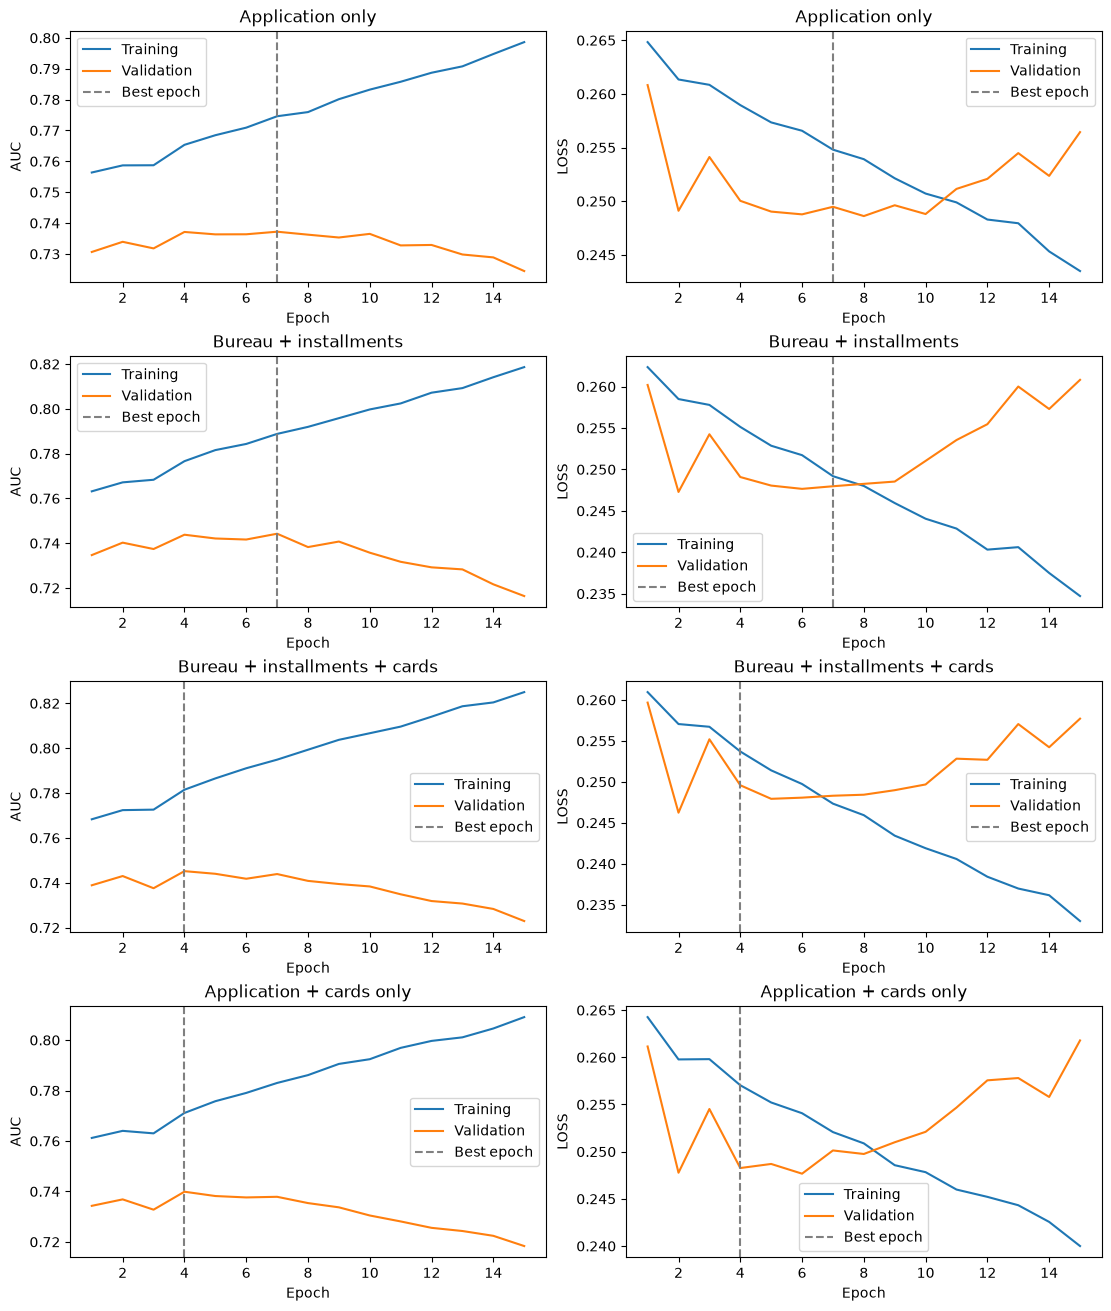

In [14]:
fig,axes = plt.subplots(4,2,figsize=(11,13),constrained_layout=True)
for row,result in zip(axes,[baseline,with_history,with_cards,card_only]):
    h = result['history']
    for ax,metric in zip(row,['auc','loss']):
        ax.plot(h.epoch,h['train_'+metric],label='Training')
        ax.plot(h.epoch,h['val_'+metric],label='Validation')
        ax.axvline(result['best_epoch'],color='gray',linestyle='--',label='Best epoch')
        ax.set(title=result['name'],xlabel='Epoch',ylabel=metric.upper())
        ax.legend()
plt.show()

## Interpretation

Use ROC AUC as the model-selection metric and report accuracy and both error types alongside F1, precision, and recall. Better AUC need not mean fewer errors at an F1-selected threshold. Examine new errors and corrected cases, then evaluate subgroup fairness before adopting the merged model.

This experiment addresses one predeclared loan-amount stress test. It does not establish that this is the best deployment split, that history improves every population, or that results are statistically significant. The highest-loan band is unscored. Splits overlap earlier project development, so disclose prior exposure in the report. No models or large prediction files are written; results and curves are saved in this notebook, with complete validation comparisons in `error_comparison` when run.


The matched-false-positive-rate comparison is also validation-tuned, not an independent estimate. Credit-card history coverage and mean/rate features are record-weighted; applicants with longer histories contribute more monthly records within their summaries.

### Credit-card experiment findings

Adding 13 card-history features increased validation AUC slightly, from **0.74423 to 0.74519**. At each model's F1-selected threshold, accuracy increased from **83.06% to 85.20%**, but F1 slipped from **0.28883 to 0.28765** and recall fell from **43.79% to 38.04%**. The selected threshold changed from **0.155 to 0.211**. False positives decreased from **8,017 to 6,359**, while false negatives increased from **2,827 to 3,116**. The card model corrected 3,041 prior errors and introduced 1,672; fewer total errors therefore did not mean fewer missed difficulties.

At a common false-positive-rate cap of **13.589%**, the bureau/installment model missed **2,827** difficulties with **8,004** false positives, while the card model missed **2,860** with **8,016** false positives. The slight difference in false-positive counts comes from selecting recall-maximizing thresholds on discrete score distributions. Card history did **not** improve detection at this comparable false-alarm level in this run.

The card model peaked at epoch 4 and overfit afterward. Only 28.26% of application applicants have eligible card records. This is one training seed on one repeatedly used validation split: the small AUC gain is not evidence of a reliable improvement. Keep card features experimental rather than claiming they reduce false negatives. The unscored test band and reusable additional-data CSV were not changed.

### Application plus credit cards only

With bureau and installment features excluded, the card-only extension achieved **AUC 0.73989**, **accuracy 84.27%**, and **F1 0.28460**, at its selected threshold of **0.173**. It produced **7,044 false positives and 3,026 false negatives**. Relative to application-only, that is 284 fewer false positives but 23 more false negatives. It corrected 1,928 original errors and introduced 1,667. Its best epoch was 4, followed by overfitting.

At the same false-positive-rate cap used for every model, false negatives were **2,900** for application-only, **2,887** for application plus cards, **2,827** for bureau plus installments, and **2,860** for bureau plus installments plus cards. Each model includes the application inputs. Actual false-positive counts were respectively 8,013, 8,016, 8,004, and 8,016. Thus cards alone gave only a small improvement over application-only in detection at comparable false alarms, and did not outperform bureau plus installments. These are single-seed validation findings, not evidence of statistical significance or final test performance.
